# Phase 10 Part 1B — CLEAN-v3 UNet++ Training Review

**Model:** Gemini 3.8 Flash Medium
**Date:** 2026-09-20
**Experiment:** `phase10_kub_unetpp_seed42_512_clean_v3`
**Architecture:** UNet++ (`unetpp_nested_4_level_no_deep_supervision`, deep supervision OFF)
**Manifest:** `phase4_v3` | **Taxonomy:** `kub_size_clean_v3_v1`

---

> **READ-ONLY REVIEWER NOTEBOOK** — does NOT train. Reviews a completed run.
> TEST locked. **No winner declared** — DeepLabV3+ has not been rerun, so no
> ranking or cross-model conclusion is valid yet.
>
> **Paired gallery:** this notebook uses the SAME frozen 16-case KUB VAL selection
> as UNet and Attention U-Net (canonical SHA `10ad09cb…`) so the three models are
> directly comparable sample-for-sample.


## 2. Scope and Governance

| Item | Value |
|------|-------|
| Manifest | `phase4_v3` |
| Taxonomy | `kub_size_clean_v3_v1` |
| Target | `mask > 0` via `binarize_mask` |
| Resolution | 512, 1 channel |
| VAL scope | KUB-only 280 (hard-gated) |
| TEST | LOCKED (reads = 0) |
| Cross-model comparison | NOT PERFORMED |

Phase 10 status: UNet (09), Attention U-Net (10-1A), UNet++ (10-1B) are complete.
**DeepLabV3+ is NOT started**, so no Phase-10 winner is declared.


In [1]:
%matplotlib inline
import sys, json
from pathlib import Path
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

PROJECT_ROOT = Path(r'D:\Softfors\jup')
sys.path.insert(0, str(PROJECT_ROOT))
sys.path.insert(0, str(PROJECT_ROOT / 'notebooks' / 'phasewise' / 'phase_10_baseline_comparison' / 'code'))
import phase10_unetpp_review as rv

print('Experiment  :', rv.EXPERIMENT_ID)
print('Architecture: unetpp (no deep supervision)')
print('Historical  :', rv.HISTORICAL_EXPERIMENT_ID)


Experiment  : phase10_kub_unetpp_seed42_512_clean_v3
Architecture: unetpp (no deep supervision)
Historical  : phase10_kub_unetpp_seed42_512


## 4. Clean-v3 Experiment Identity


In [2]:
print('=== EXPERIMENT IDENTITY ===')
print(f'Experiment ID : {rv.EXPERIMENT_ID}')
print(f'Architecture  : unetpp_nested_4_level_no_deep_supervision')
print(f'Deep supervis.: OFF (single final head)')
print(f'Config SHA    : {rv.EXPECTED_CONFIG_SHA}')
print(f'History SHA   : {rv.EXPECTED_HISTORY_SHA}')
print(f'Best pt SHA   : {rv.EXPECTED_BEST_SHA}')
print(f'Latest pt SHA : {rv.EXPECTED_LATEST_SHA}')
print(f'Manifest      : phase4_v3')
print(f'Taxonomy      : kub_size_clean_v3_v1')


=== EXPERIMENT IDENTITY ===
Experiment ID : phase10_kub_unetpp_seed42_512_clean_v3
Architecture  : unetpp_nested_4_level_no_deep_supervision
Deep supervis.: OFF (single final head)
Config SHA    : e2788e504b09cd8544e45fb7aef4001b8363452963d7d793f693647b4df24f53
History SHA   : a733d8366278d2ddb1a44db0d94ff7525fb9b10afefba787abfd036c1fb1de5a
Best pt SHA   : ec7eb13f32e43af27eab7fc617bd1a2a8fcce1d6651a1b4a3653f3e4d1283269
Latest pt SHA : 77a39b4f510f69956233af898f7f62d4ae755fac57375bab70f95102b142c8ef
Manifest      : phase4_v3
Taxonomy      : kub_size_clean_v3_v1


## 5. Frozen Protocol (from physical config)


In [3]:
cfg = rv.load_config()
m, t, o, s, a = cfg['model'], cfg['training'], cfg['optimizer'], cfg['scheduler'], cfg['augmentation']
print('=== FROZEN PROTOCOL ===')
print(f"Architecture  : {m['name']} (deep_supervision={m.get('deep_supervision')})")
print(f"In/Out/Base   : {m['input_channels']} / {m['output_channels']} / {m['base_channels']}")
print(f"Resolution    : {cfg['input_resolution']}")
print(f"Preprocessing : {cfg['preprocessing']['strategy']} ({cfg['preprocessing']['mask_interpolation']} mask)")
print(f"Loss          : {cfg['loss']['name']} {cfg['loss']['bce_weight']}/{cfg['loss']['dice_weight']} eps={cfg['loss']['dice_epsilon']}")
print(f"Optimizer     : {o['name']} lr={o['learning_rate']} wd={o['weight_decay']}")
print(f"Scheduler     : {s['name']} T_max={s['max_epochs']}")
print(f"Batch         : {t['batch_size']} (accum {t['gradient_accumulation_steps']}, eff {t['effective_batch_size']})")
print(f"AMP / seed    : {t['amp']} / {t['seed']}")
print(f"Max epochs    : {t['max_epochs']}  patience {t['early_stopping_patience']}")
print(f"Monitor/thresh: {t['monitor']} / {t['threshold']}")
print(f"Augmentation  : hflip={a['horizontal_flip_probability']} rot=+/-{a['rotation_degrees']} bright=+/-{a['brightness']} contrast=+/-{a['contrast']} vflip={a['vertical_flip']}")
print(f"Init          : {cfg['initialization']['policy']}")
print(f"allow_test    : {cfg['allow_test']}")


=== FROZEN PROTOCOL ===
Architecture  : unetpp (deep_supervision=False)
In/Out/Base   : 1 / 1 / 32
Resolution    : 512
Preprocessing : aspect_ratio_resize_symmetric_pad (nearest mask)
Loss          : bce_dice 0.5/0.5 eps=1e-06
Optimizer     : AdamW lr=0.0001 wd=0.0001
Scheduler     : CosineAnnealingLR T_max=100
Batch         : 4 (accum 1, eff 4)
AMP / seed    : True / 42
Max epochs    : 100  patience 15
Monitor/thresh: val_macro_dice / 0.5
Augmentation  : hflip=0.5 rot=+/-5.0 bright=+/-0.1 contrast=+/-0.1 vflip=False
Init          : random_kaiming_no_pretrained_weights
allow_test    : False


## 6. Protocol-Diff Audit (v2 -> clean-v3)


In [4]:
d = rv.load_protocol_diff()
print('=== PROTOCOL DIFF ===')
print('Total fields compared:', len(d))
print('CHANGED:', int((d['same_or_changed'] == 'CHANGED').sum()))
print('SAME   :', int((d['same_or_changed'] == 'SAME').sum()))
print()
print(d[d['same_or_changed'] == 'CHANGED'][['field', 'historical_v2', 'clean_v3', 'change_reason']].to_string(index=False))
print()
unauth = d[(d['same_or_changed'] == 'CHANGED') & (d['scientifically_material'] == True)]
print('Unauthorized material differences:', len(unauth))
assert len(unauth) == 0, 'Unauthorized material differences present!'
print('All changes are governance/provenance only - PASS')


=== PROTOCOL DIFF ===
Total fields compared: 47
CHANGED: 8
SAME   : 39

             field                 historical_v2                               clean_v3                                        change_reason
     experiment_id phase10_kub_unetpp_seed42_512 phase10_kub_unetpp_seed42_512_clean_v3                              Clean-v3 logical run ID
  manifest_version                     phase4_v2                              phase4_v3              Clean manifest with leakage remediation
       taxonomy_id                           NaN                   kub_size_clean_v3_v1                              Frozen taxonomy binding
           monitor val_macro_dice_true_per_image                         val_macro_dice Canonical monitor string (identical macro semantics)
   device_contract                      implicit          get_device(require_cuda=True)                              Fail-loud CUDA contract
   target_contract                      implicit               binarize_mask (mask

## 7. History Integrity (independent from physical CSV)


In [5]:
df = rv.load_history()
hi = rv.check_history_integrity(df)
print('=== HISTORY INDEPENDENT RECONSTRUCTION ===')
for k, v in hi.items():
    print(f'  {k}: {v}')
assert hi['best_epoch'] == 70
assert hi['unique_strict_max']
assert hi['final_epoch'] == 85
assert hi['final_bad_epochs'] == 15
assert hi['stop_consistent']
assert hi['contiguous_epochs'] and hi['no_duplicates']
assert hi['no_nan'] and hi['finite_losses']
print()
print('HISTORY INTEGRITY - PASS  (70 + 15 = 85 early stop)')


=== HISTORY INDEPENDENT RECONSTRUCTION ===
  row_count: 85
  contiguous_epochs: True
  no_duplicates: True
  best_epoch: 70
  best_val_dice: 0.7641595156062713
  best_val_iou: 0.6525442690586191
  best_val_precision: 0.7996825971468945
  best_val_recall: 0.791238416956199
  unique_strict_max: True
  final_epoch: 85
  final_bad_epochs: 15
  stop_consistent: True
  improved_count: 21
  no_nan: True
  finite_losses: True

HISTORY INTEGRITY - PASS  (70 + 15 = 85 early stop)


## 8. Training Convergence


In [6]:
b = df.loc[df['val_dice'].idxmax()]
print('=== CONVERGENCE ===')
print(f'Epochs            : {len(df)}')
print(f'Best epoch        : {int(b["epoch"])}')
print(f'Best VAL Dice     : {b["val_dice"]:.16f}')
print(f'Best VAL IoU      : {b["val_iou"]:.16f}')
print(f'Best VAL Precision: {b["val_precision"]:.16f}')
print(f'Best VAL Recall   : {b["val_recall"]:.16f}')
print(f'Final epoch       : {int(df["epoch"].iloc[-1])}')
print(f'Final bad_epochs  : {int(df["bad_epochs"].iloc[-1])}')
print(f'Improvements      : {int(df["improved"].sum())}')
print(f'Train loss first/last: {df["train_loss"].iloc[0]:.6f} / {df["train_loss"].iloc[-1]:.6f}')
print(f'VAL loss first/last  : {df["val_loss"].iloc[0]:.6f} / {df["val_loss"].iloc[-1]:.6f}')
print(f'Mean epoch seconds   : {df["epoch_seconds"].mean():.1f}')
print()
print('=== EARLY-STOP VERIFICATION ===')
print(f'best epoch {int(b["epoch"])} + patience 15 = {int(b["epoch"]) + 15}; actual stop = {int(df["epoch"].iloc[-1])}')
assert int(df['epoch'].iloc[-1]) == int(b['epoch']) + 15
print('Early-stop consistent - PASS')


=== CONVERGENCE ===


Epochs            : 85
Best epoch        : 70
Best VAL Dice     : 0.7641595156062713
Best VAL IoU      : 0.6525442690586191
Best VAL Precision: 0.7996825971468945
Best VAL Recall   : 0.7912384169561990
Final epoch       : 85
Final bad_epochs  : 15
Improvements      : 21
Train loss first/last: 0.438780 / 0.142067
VAL loss first/last  : 0.416830 / 0.199979
Mean epoch seconds   : 180.6

=== EARLY-STOP VERIFICATION ===
best epoch 70 + patience 15 = 85; actual stop = 85
Early-stop consistent - PASS


## 9. Best-Checkpoint Verification


In [7]:
bck = rv.check_best_checkpoint_consistency()
print('=== BEST CHECKPOINT ===')
for k, v in bck.items():
    print(f'  {k}: {v}')
assert bck['all_pass']
print('\nBEST CHECKPOINT - PASS')


=== BEST CHECKPOINT ===
  epoch_matches: True
  experiment_id_matches: True
  manifest_matches: True
  taxonomy_matches: True
  seed_matches: True
  model_matches: True
  resolution_matches: True
  threshold_matches: True
  score_agrees_with_history: True
  all_pass: True
  epoch: 70
  best_metric: 0.7641595156062713
  bad_epochs: 0

BEST CHECKPOINT - PASS


In [8]:
lck = rv.check_latest_checkpoint_consistency()
print('=== LATEST CHECKPOINT ===')
for k, v in lck.items():
    print(f'  {k}: {v}')
assert lck['all_pass']
print('\nLATEST CHECKPOINT - PASS')


=== LATEST CHECKPOINT ===
  epoch_matches: True
  experiment_id_matches: True
  manifest_matches: True
  taxonomy_matches: True
  seed_matches: True
  model_matches: True
  bad_epochs_matches: True
  all_pass: True
  epoch: 85
  bad_epochs: 15

LATEST CHECKPOINT - PASS


## 10. Early-Stop Verification

Ordering preserved exactly as in the historical trainer
(`scripts/training/train_phase10_baselines.py`):

`TRAIN -> VAL -> scheduler.step() -> strict '>' improvement -> early_stopping.update()
-> save latest (always) -> save best (if improved) -> stop check`


In [9]:
print('=== ORDERING & STOP ===')
print('Ordering : TRAIN -> VAL -> scheduler.step -> improvement -> early-stop -> latest -> best -> stop')
print('Improvement rule: strict > (ties = bad epoch)')
print(f'Best epoch      : {int(b["epoch"])}')
print(f'Consecutive bad : {int(df["bad_epochs"].iloc[-1])}')
print(f'Stopped at      : {int(df["epoch"].iloc[-1])}')
print(f'Stop reason     : EARLY_STOP')
print()
print('Scheduler advanced on the final epoch as well (historical behaviour).')
print('Early-stop verification - PASS')


=== ORDERING & STOP ===
Ordering : TRAIN -> VAL -> scheduler.step -> improvement -> early-stop -> latest -> best -> stop
Improvement rule: strict > (ties = bad epoch)
Best epoch      : 70
Consecutive bad : 15
Stopped at      : 85
Stop reason     : EARLY_STOP

Scheduler advanced on the final epoch as well (historical behaviour).
Early-stop verification - PASS


## 11. KUB-Only VAL Scope


In [10]:
val_all = pd.read_csv(PROJECT_ROOT / 'manifests' / 'phase4_v3' / 'val.csv')
print('Full phase4_v3 VAL rows:', len(val_all))
print('Datasets:', val_all['dataset'].value_counts().to_dict())
kub_val = rv.get_kub_val()
scope = rv.assert_kub_scope(kub_val)
print()
print('=== KUB-ONLY VAL ===')
for k, v in scope.items():
    print(f'  {k}: {v}')
print('Category counts:', kub_val['category'].value_counts().to_dict())
print('Acquisition    :', kub_val['acquisition_type'].value_counts().to_dict())
assert len(kub_val) == 280 and scope['not_available_count'] == 0 and scope['unknown_acquisition_count'] == 0
print('\nKUB-ONLY VAL - PASS')


Full phase4_v3 VAL rows: 808
Datasets: {'ISIC': 357, 'KUB': 280, 'KVASIR': 87, 'BUSI': 84}

=== KUB-ONLY VAL ===
  all_kub: True
  row_count: 280
  categories: {'Bladder_Stone', 'Ureteric_Stone', 'Kidney_Stone'}
  not_available_count: 0
  unknown_acquisition_count: 0
  all_pass: True
Category counts: {'Bladder_Stone': 144, 'Kidney_Stone': 112, 'Ureteric_Stone': 24}
Acquisition    : {'ROI': 177, 'FULL_FIELD': 103}

KUB-ONLY VAL - PASS


## 12. Frozen Paired Gallery Selection

The SAME 16 KUB VAL sample IDs used for UNet and Attention U-Net. SHA verified.


In [11]:
gallery_df = rv.load_canonical_gallery(kub_val)
print('Canonical gallery SHA verified:', rv.CANONICAL_GALLERY_SHA)
print('Actual file SHA              :', rv.sha256_file(rv.CANONICAL_GALLERY))
print(f'Cases: {len(gallery_df)}')
print(gallery_df[['gallery_index', 'sample_id', 'category', 'acquisition_type']].to_string(index=False))
assert len(gallery_df) == 16
assert set(gallery_df['category']).issubset({'Kidney_Stone', 'Bladder_Stone', 'Ureteric_Stone'})
assert gallery_df['acquisition_type'].isin(['ROI', 'FULL_FIELD']).all()
print()
print('Selection identical to UNet / Attention U-Net galleries - PASS')


Canonical gallery SHA verified: 10ad09cbcaabb56bc6bc6aefe016c83b2173933bf6d1f16e4baaf3f0845613db
Actual file SHA              : 10ad09cbcaabb56bc6bc6aefe016c83b2173933bf6d1f16e4baaf3f0845613db
Cases: 16
 gallery_index                        sample_id       category acquisition_type
             1 00849cbfea1e926cc0bf0443c9a57ac0   Kidney_Stone              ROI
             2 0144956d1749caca131daae62fb5f59a  Bladder_Stone              ROI
             3 033668e32b8f9d46165c01d8b9e1e111 Ureteric_Stone              ROI
             4 0785b56594049121d6281aa40e475e26  Bladder_Stone       FULL_FIELD
             5 08d0d5ec1c23988253c6bbd519908e7d   Kidney_Stone       FULL_FIELD
             6 1f7039f2079e8d2e6cb4cac6daa062b3  Bladder_Stone              ROI
             7 416e6f7d9e35c6bf4bde51e191a7e92d Ureteric_Stone       FULL_FIELD
             8 7740904a921b977a9885955d8d58f991  Bladder_Stone              ROI
             9 9057aec09b055e6542208d6f7bf518f6  Bladder_Stone              R

## 13. Training Curves


Curves saved: D:\Softfors\jup\reports\figures\phase10_unetpp_clean_v3_training_curves_review.png


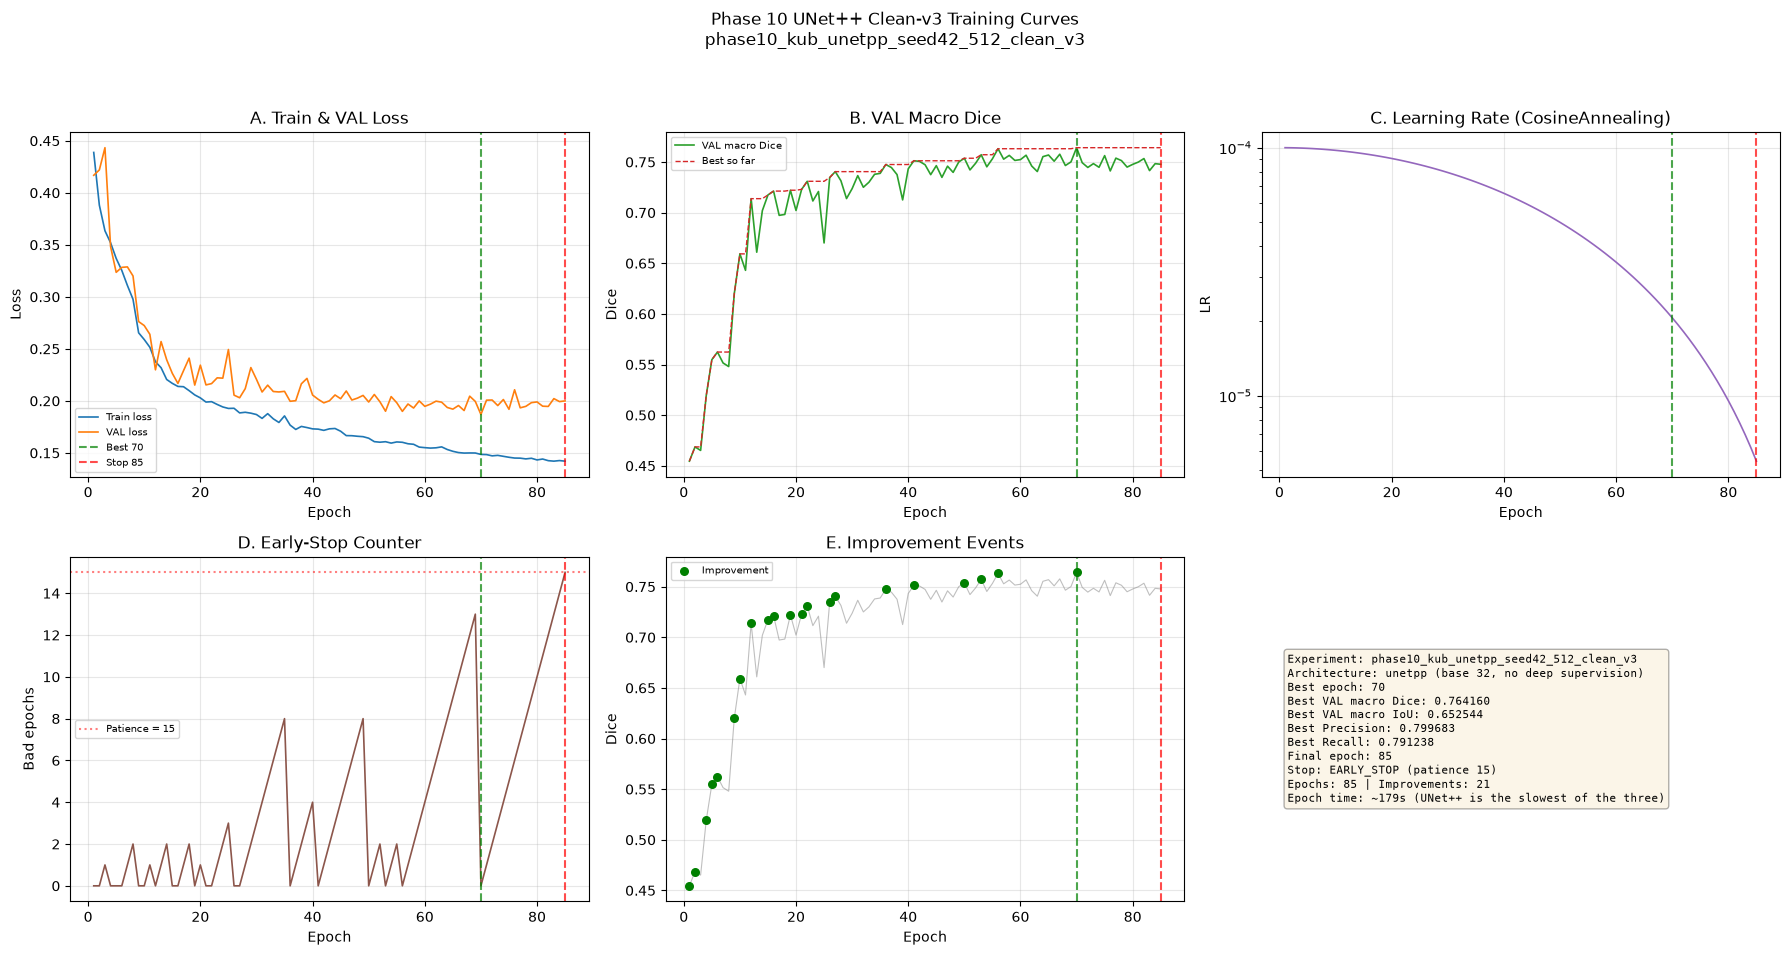

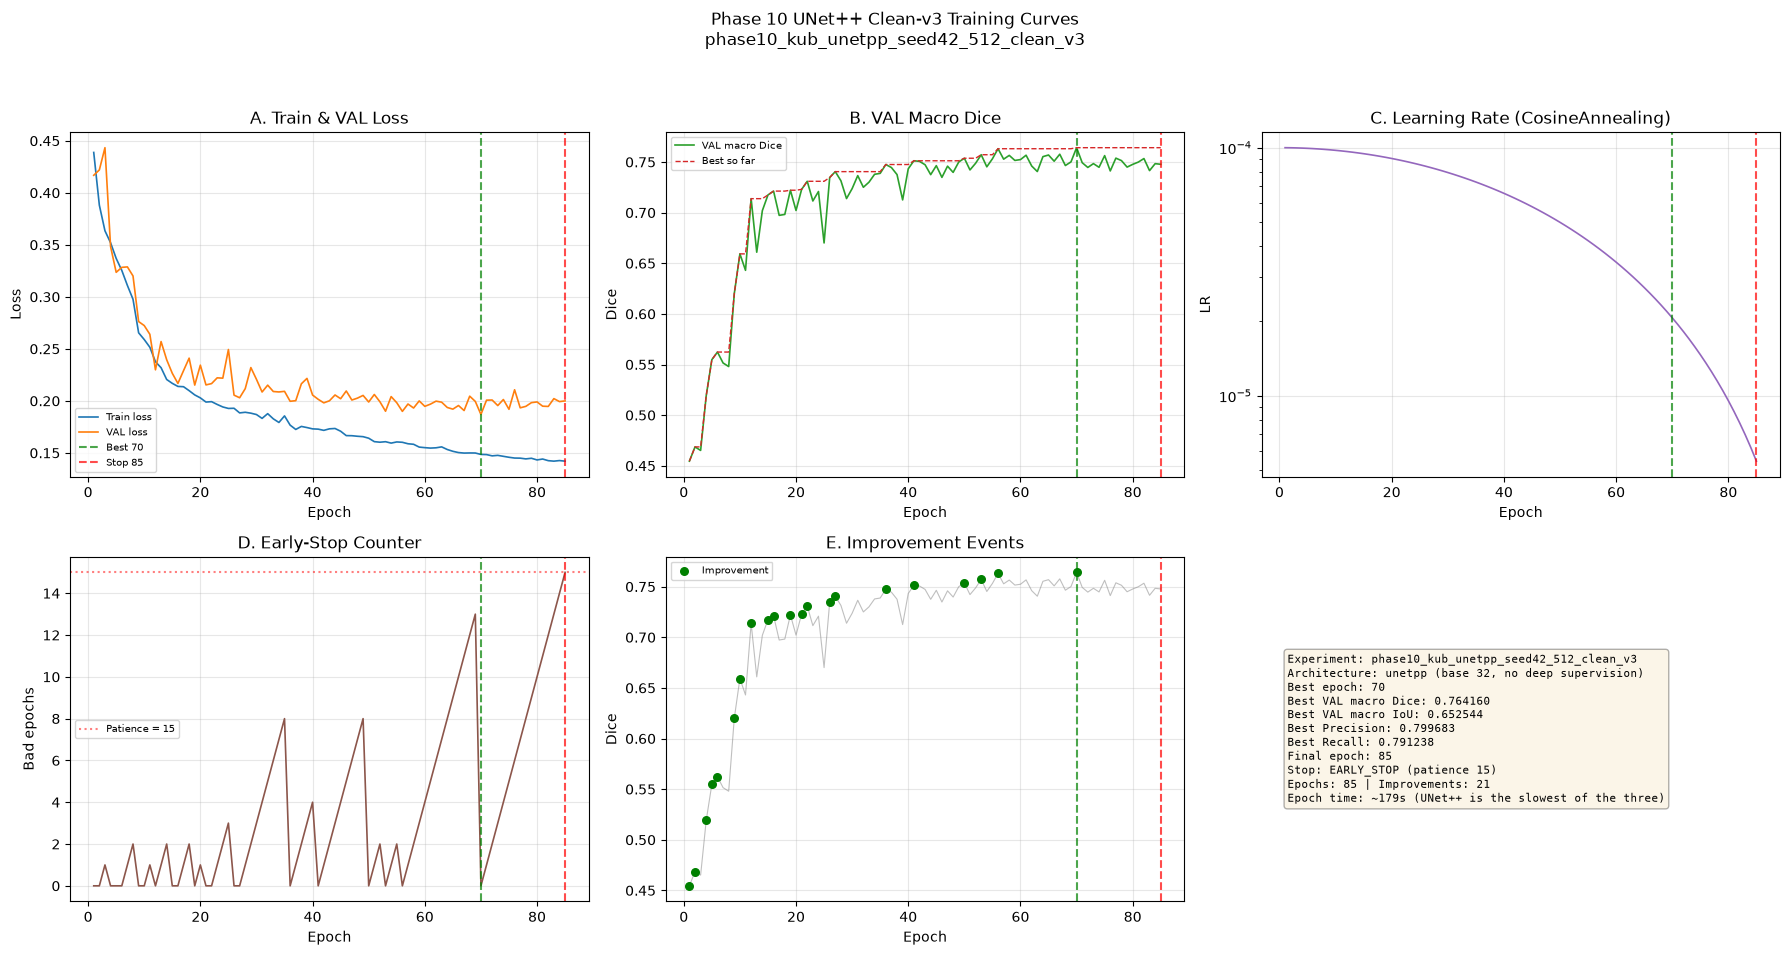

In [12]:
fig = rv.plot_training_curves(df)
cp = PROJECT_ROOT / 'reports' / 'figures' / 'phase10_unetpp_clean_v3_training_curves_review.png'
fig.savefig(cp, dpi=150, bbox_inches='tight')
print(f'Curves saved: {cp}')
display(fig)


## 14. UNet++ VAL Prediction Gallery

best.pt only (epoch 70), threshold 0.5, identical 16 cases to the other models.

> Metrics are `DETERMINISTIC_GALLERY_SUBSET_ONLY` — not overall VAL scores.


In [13]:
from src.utils.targets import binarize_mask
from src.metrics.segmentation import binary_metrics

model, device = rv.load_best_model_for_inference(device='cuda')
print(f'Model on {device}: {model.__class__.__name__}')
print(f'Parameters: {sum(p.numel() for p in model.parameters()):,}')
print()
print('=== PRE-CHECK ===')
for _, row in gallery_df.iterrows():
    ie, me = Path(row['image_path']).exists(), Path(row['mask_path']).exists()
    print(f"  {row['gallery_index']:2d} {row['sample_id'][:26]:26s} {'OK' if (ie and me) else 'MISSING'}")


Model on cuda:0: UNetPlusPlus
Parameters: 9,159,105

=== PRE-CHECK ===
   1 00849cbfea1e926cc0bf0443c9 OK
   2 0144956d1749caca131daae62f OK
   3 033668e32b8f9d46165c01d8b9 OK
   4 0785b56594049121d6281aa40e OK
   5 08d0d5ec1c23988253c6bbd519 OK
   6 1f7039f2079e8d2e6cb4cac6da OK
   7 416e6f7d9e35c6bf4bde51e191 OK
   8 7740904a921b977a9885955d8d OK
   9 9057aec09b055e6542208d6f7b OK
  10 b0473630de9211114c94c7dc03 OK
  11 b5807d0c333c88ffc8b93d118f OK
  12 c601e447d2efb705941e8b1ec6 OK
  13 d5b2162ad4c439d90f5483fe46 OK
  14 ec7d4690db3c071ecd012b3594 OK
  15 f1afd69d82aff6da8bc39cdcd5 OK
  16 f62138e1d57921c98a7fa5cb53 OK


Gallery saved: D:\Softfors\jup\reports\figures\phase10_unetpp_clean_v3_val_gallery.png


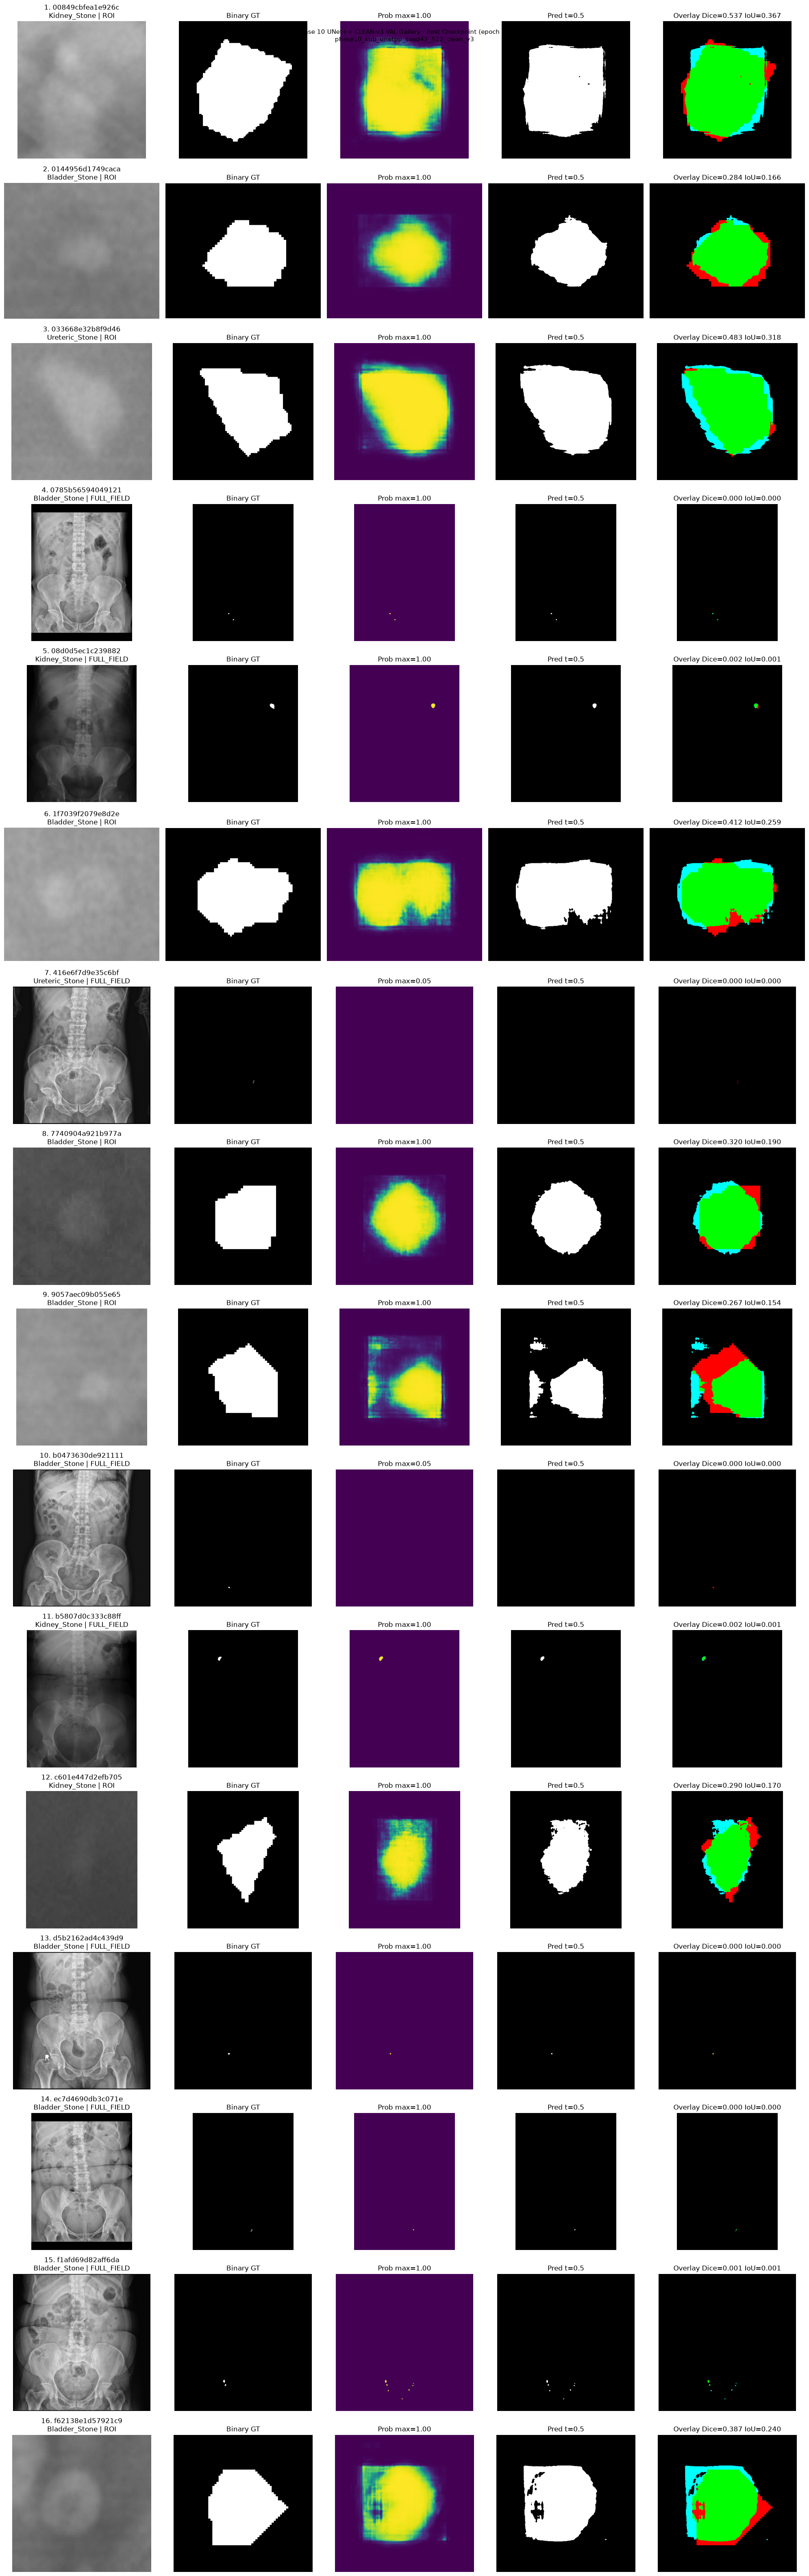

Metrics saved: D:\Softfors\jup\reports\tables\phase10_unetpp_clean_v3_val_gallery_metrics.csv

=== DETERMINISTIC_GALLERY_SUBSET_ONLY ===
Subset mean Dice: 0.186556
Subset mean IoU : 0.116675

Authoritative full-KUB-VAL (280 cases, epoch 70):
  Dice=0.7641595156062713 IoU=0.6525442690586191
  Precision=0.7996825971468945 Recall=0.7912384169561990

Gallery means do NOT replace authoritative metrics.


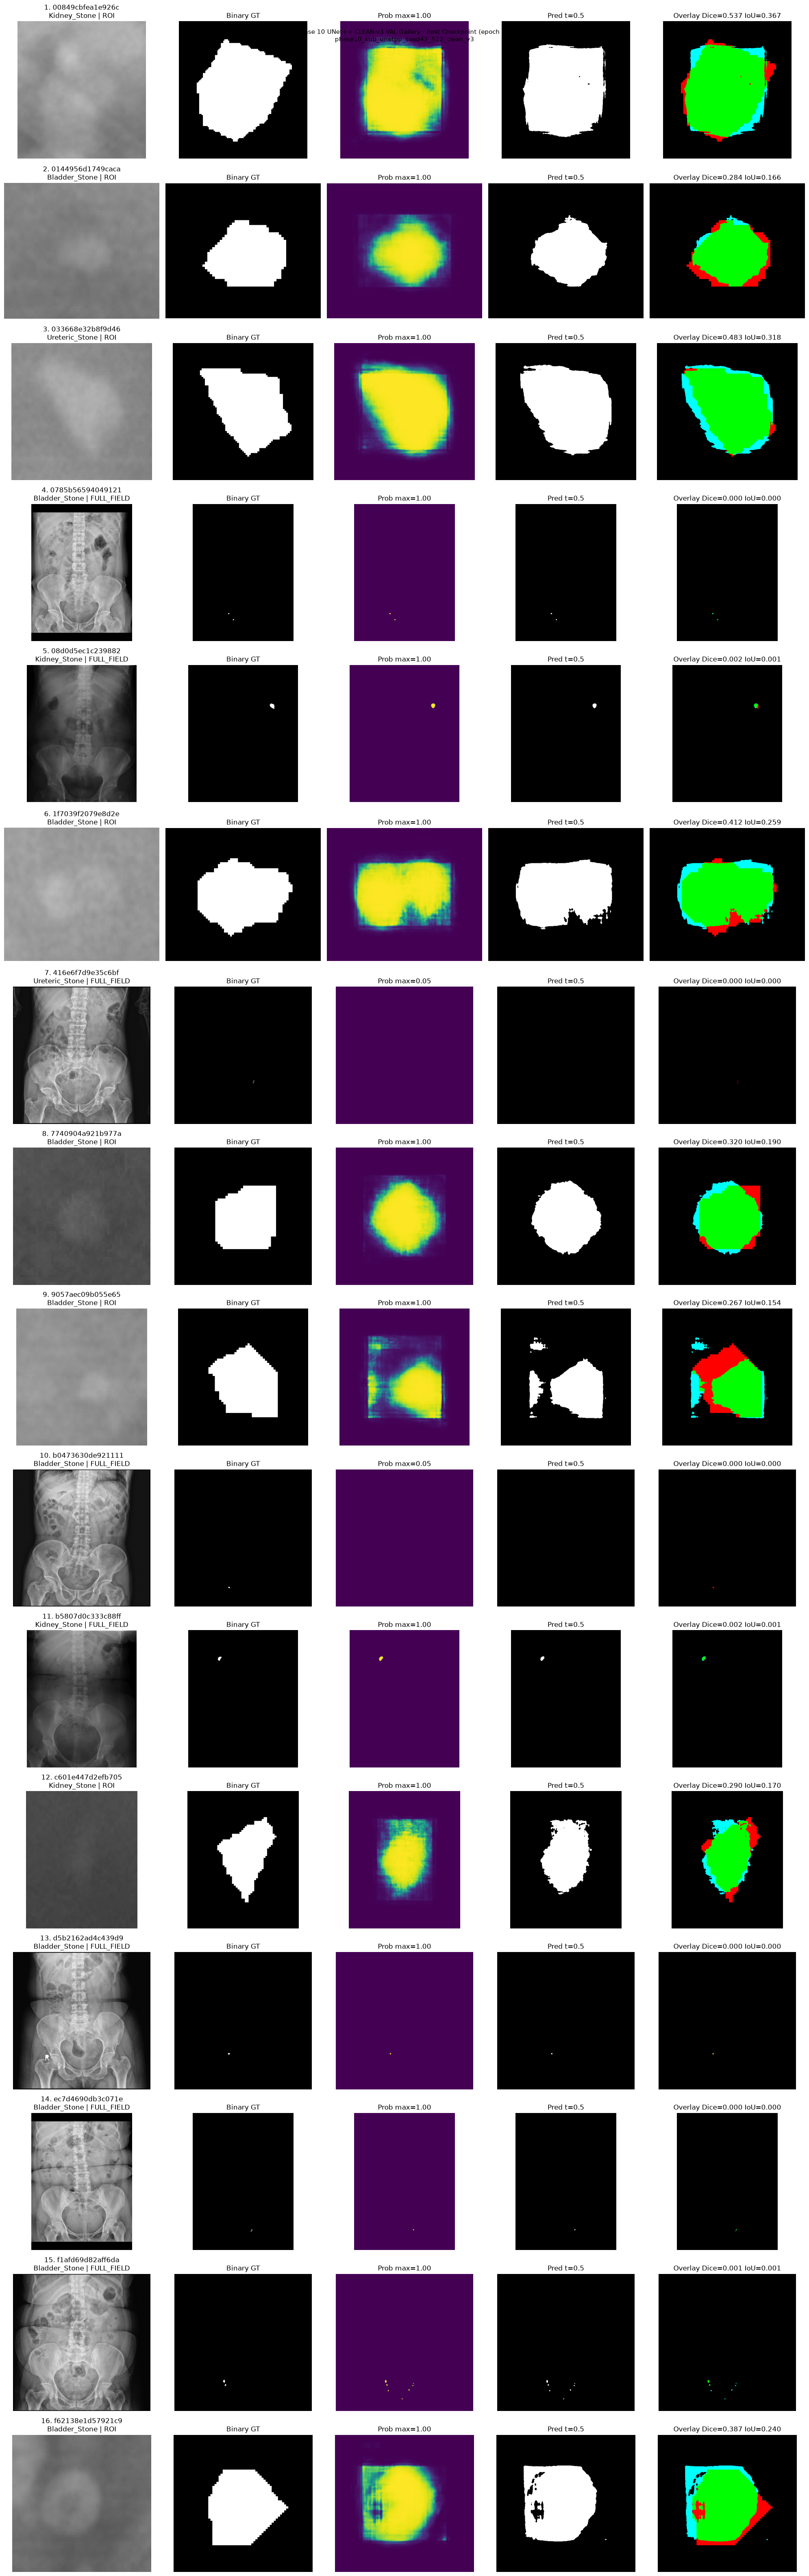

In [14]:
n = len(gallery_df)
fig, axes = plt.subplots(n, 5, figsize=(20, 4 * n))
fig.suptitle(f'Phase 10 UNet++ CLEAN-v3 VAL Gallery - Best Checkpoint (epoch 70)\n{rv.EXPERIMENT_ID}', fontsize=11)
TH = 0.5
records = []

for idx, (_, row) in enumerate(gallery_df.iterrows()):
    sid = row['sample_id']
    ip, mp = Path(row['image_path']), Path(row['mask_path'])
    if not ip.exists() or not mp.exists():
        for ax in axes[idx]:
            ax.axis('off'); ax.set_title('MISSING')
        continue

    gt = binarize_mask(np.array(Image.open(mp).convert('L'))).astype(np.uint8)
    prob, (nw, nh), (pl, pt) = rv.predict_on_val_sample(model, device, ip, target_size=512)
    gtr = np.array(Image.fromarray(gt).resize((nw, nh), Image.NEAREST))
    pred = (prob >= TH).astype(np.uint8)
    m = binary_metrics(torch.from_numpy(gtr).float().unsqueeze(0),
                       torch.from_numpy(pred).float().unsqueeze(0), threshold=0.5)
    dice, iou = float(m['dice']), float(m['iou'])

    im = Image.open(ip).convert('L'); native = im.size; arr = np.array(im)
    ov = np.zeros((*pred.shape, 3), dtype=np.uint8)
    ov[..., 0] = gtr * 255; ov[..., 1] = pred * 255
    both = gtr & pred
    ov[..., 0] = np.where(both, 0, ov[..., 0]); ov[..., 1] = np.where(both, 255, ov[..., 1])
    ov[..., 2] = np.where((gtr == 0) & (pred == 1), 255, 0)

    A = axes[idx]
    A[0].imshow(arr, cmap='gray', vmin=0, vmax=255)
    A[0].set_title(f'{idx+1}. {sid[:16]}\n{row["category"]} | {row["acquisition_type"]}')
    A[1].imshow(gtr, cmap='gray', vmin=0, vmax=1); A[1].set_title('Binary GT')
    A[2].imshow(prob, cmap='viridis', vmin=0, vmax=1); A[2].set_title(f'Prob max={prob.max():.2f}')
    A[3].imshow(pred, cmap='gray', vmin=0, vmax=1); A[3].set_title(f'Pred t={TH}')
    A[4].imshow(ov); A[4].set_title(f'Overlay Dice={dice:.3f} IoU={iou:.3f}')
    for ax in A: ax.axis('off')

    records.append({'gallery_index': idx + 1, 'sample_id': sid, 'patient_id': row['patient_id'],
                    'category': row['category'], 'acquisition_type': row['acquisition_type'],
                    'native_width': native[0], 'native_height': native[1],
                    'pred_width': nw, 'pred_height': nh, 'dice': dice, 'iou': iou})

plt.tight_layout()
gf = PROJECT_ROOT / 'reports' / 'figures' / 'phase10_unetpp_clean_v3_val_gallery.png'
fig.savefig(gf, dpi=150, bbox_inches='tight')
print(f'Gallery saved: {gf}')
display(fig)

mdf = pd.DataFrame(records)
mpath = PROJECT_ROOT / 'reports' / 'tables' / 'phase10_unetpp_clean_v3_val_gallery_metrics.csv'
mdf.to_csv(mpath, index=False)
print(f'Metrics saved: {mpath}')
print()
print('=== DETERMINISTIC_GALLERY_SUBSET_ONLY ===')
print(f'Subset mean Dice: {mdf["dice"].mean():.6f}')
print(f'Subset mean IoU : {mdf["iou"].mean():.6f}')
print()
print('Authoritative full-KUB-VAL (280 cases, epoch 70):')
print(f'  Dice={b["val_dice"]:.16f} IoU={b["val_iou"]:.16f}')
print(f'  Precision={b["val_precision"]:.16f} Recall={b["val_recall"]:.16f}')
print()
print('Gallery means do NOT replace authoritative metrics.')


## 15. Aggregate Authoritative VAL Metrics


In [15]:
b = df.loc[df['val_dice'].idxmax()]
summary = pd.DataFrame([{
    'experiment_id': rv.EXPERIMENT_ID, 'architecture': 'unetpp',
    'manifest_version': 'phase4_v3', 'taxonomy_id': 'kub_size_clean_v3_v1',
    'best_epoch': int(b['epoch']), 'best_val_macro_dice': float(b['val_dice']),
    'val_macro_iou': float(b['val_iou']), 'val_precision': float(b['val_precision']),
    'val_recall': float(b['val_recall']), 'final_epoch': int(df['epoch'].iloc[-1]),
    'stop_reason': 'EARLY_STOP', 'early_stop_bad_epochs': int(df['bad_epochs'].iloc[-1]),
    'config_sha': rv.EXPECTED_CONFIG_SHA, 'history_sha': rv.EXPECTED_HISTORY_SHA,
    'best_checkpoint_sha': rv.EXPECTED_BEST_SHA, 'latest_checkpoint_sha': rv.EXPECTED_LATEST_SHA,
}])
sp = PROJECT_ROOT / 'reports' / 'tables' / 'phase10_unetpp_clean_v3_best_val_summary.csv'
summary.to_csv(sp, index=False)
print(f'Saved: {sp}')
print(summary.T.to_string())


Saved: D:\Softfors\jup\reports\tables\phase10_unetpp_clean_v3_best_val_summary.csv
                                                                                      0
experiment_id                                    phase10_kub_unetpp_seed42_512_clean_v3
architecture                                                                     unetpp
manifest_version                                                              phase4_v3
taxonomy_id                                                        kub_size_clean_v3_v1
best_epoch                                                                           70
best_val_macro_dice                                                             0.76416
val_macro_iou                                                                  0.652544
val_precision                                                                  0.799683
val_recall                                                                     0.791238
final_epoch                          

## 16. Limitations

1. VAL-only; TEST locked (reads = 0).
2. Reviews UNet++ only.
3. **No winner / ranking / statistical test** — DeepLabV3+ not rerun.
4. Gallery metrics are `DETERMINISTIC_GALLERY_SUBSET_ONLY`.
5. Historical-v2 comparison is not a controlled experiment (different populations).
6. UNet++ is the slowest model (~179 s/epoch vs ~72 s Attention U-Net); run took ~4.3 h.


## 17. Historical-v2 Separation

| Property | HISTORICAL_v2 | CLEAN_v3 |
|----------|---------------|----------|
| Experiment | `phase10_kub_unetpp_seed42_512` | `…_clean_v3` |
| Manifest | `phase4_v2` | `phase4_v3` |
| Taxonomy | None | `kub_size_clean_v3_v1` |
| Best epoch | 77 | 70 |
| Final epoch | 92 | 85 |
| Best VAL Dice | 0.7625221610069275 | 0.7641595156062713 |

Clean-v3 is +0.0016; different TRAIN/VAL membership, so this is not attributed
solely to leakage remediation.


## 18. Phase-10 Current Status

| Model | clean-v3 status | Best VAL Dice |
|-------|-----------------|---------------|
| UNet (Phase 09) | COMPLETE | 0.740613 |
| Attention U-Net (10-1A) | COMPLETE | 0.752513 |
| **UNet++ (10-1B)** | **COMPLETE** | **0.764160** |
| DeepLabV3+ | NOT STARTED | — |

**No winner is declared.** DeepLabV3+ must be rerun before any conclusion.


## 19. Artifact Hashes


In [16]:
summ = rv.full_integrity_summary()
print('Overall pass:', summ['overall_pass'])
assert summ['overall_pass']

def _s(p): return rv.sha256_file(Path(p))
rel = PROJECT_ROOT
reg = pd.DataFrame([
    {'artifact': 'config', 'sha256': _s(rv.CONFIG_PATH)},
    {'artifact': 'history', 'sha256': _s(rv.HISTORY_PATH)},
    {'artifact': 'best_checkpoint', 'sha256': _s(rv.BEST_PT)},
    {'artifact': 'latest_checkpoint', 'sha256': _s(rv.LATEST_PT)},
    {'artifact': 'taxonomy', 'sha256': _s(rv.TAXONOMY_ARTIFACT)},
    {'artifact': 'training_runner', 'sha256': _s(rv.TRAINING_RUNNER)},
    {'artifact': 'protocol_diff', 'sha256': _s(rv.PROTOCOL_DIFF)},
    {'artifact': 'review_support_code', 'sha256': _s(rel/'notebooks'/'phasewise'/'phase_10_baseline_comparison'/'code'/'phase10_unetpp_review.py')},
    {'artifact': 'canonical_gallery_selection', 'sha256': rv.CANONICAL_GALLERY_SHA},
    {'artifact': 'gallery_metrics', 'sha256': _s(rel/'reports'/'tables'/'phase10_unetpp_clean_v3_val_gallery_metrics.csv')},
    {'artifact': 'best_val_summary', 'sha256': _s(rel/'reports'/'tables'/'phase10_unetpp_clean_v3_best_val_summary.csv')},
])
rp = rel / 'reports' / 'tables' / 'phase10_unetpp_clean_v3_artifact_registry.csv'
reg.to_csv(rp, index=False)
print(f'Registry saved: {rp}')
print(reg.to_string(index=False))


Overall pass: True
Registry saved: D:\Softfors\jup\reports\tables\phase10_unetpp_clean_v3_artifact_registry.csv
                   artifact                                                           sha256
                     config e2788e504b09cd8544e45fb7aef4001b8363452963d7d793f693647b4df24f53
                    history a733d8366278d2ddb1a44db0d94ff7525fb9b10afefba787abfd036c1fb1de5a
            best_checkpoint ec7eb13f32e43af27eab7fc617bd1a2a8fcce1d6651a1b4a3653f3e4d1283269
          latest_checkpoint 77a39b4f510f69956233af898f7f62d4ae755fac57375bab70f95102b142c8ef
                   taxonomy 89031c51a35c24f6f939fd6206fde6002a019d4bda24ce8cb21988f04db0f0d6
            training_runner 096a084dcc66cc4da5db53418f69f094217009406494951629816f3ca4d82b58
              protocol_diff 01a83e62112e5f9d4e84366f07c3fab32e34dc5a7a45adfd53a1a62b8b8a8562
        review_support_code f4d7c90c6a4eb3807852550a7133726c0079bd15159b841054e470c5691901af
canonical_gallery_selection 10ad09cbcaabb56bc6bc6ae

## 20. Stop Boundary


In [17]:
print('=== REVIEWER BOUNDARY ===')
print('Optimizer steps        : 0')
print('Training epochs        : 0')
print('Checkpoint writes      : 0')
print('best/latest modified   : NO')
print('history/config modified: NO')
print('TEST image/mask reads  : 0')
print('TEST metrics / visuals : 0')
print('DeepLabV3+ started     : NO')
print('Final comparison       : NOT STARTED')
print('Winner declared        : NO')
print('\nREVIEWER BOUNDARY - PASS')


=== REVIEWER BOUNDARY ===
Optimizer steps        : 0
Training epochs        : 0
Checkpoint writes      : 0
best/latest modified   : NO
history/config modified: NO
TEST image/mask reads  : 0
TEST metrics / visuals : 0
DeepLabV3+ started     : NO
Final comparison       : NOT STARTED
Winner declared        : NO

REVIEWER BOUNDARY - PASS
